In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()

# If the notebook's working directory is not the project root,
# locate the project root using this script's known folder structure.
if not (PROJECT_ROOT / "data" / "raw").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw" / "Challenge_Data"

columns = [
    "engine_id", "cycle",
    "setting_1", "setting_2", "setting_3",
] + [f"sensor_{i}" for i in range(1, 22)]

train = pd.read_csv(
    DATA_DIR / "train.txt",
    sep=r"\s+",
    header=None,
    names=columns,
)

test = pd.read_csv(
    DATA_DIR / "test.txt",
    sep=r"\s+",
    header=None,
    names=columns,
)

print("Training shape:", train.shape)
print("Test shape:", test.shape)
print("Training engines:", train["engine_id"].nunique())
print("Test engines:", test["engine_id"].nunique())


Training shape: (45918, 26)
Test shape: (29820, 26)
Training engines: 218
Test engines: 218


Training engine lifetime statistics:
count    218.00
mean     210.63
std       43.60
min      128.00
25%      177.00
50%      209.50
75%      236.00
max      357.00
Name: cycle, dtype: float64


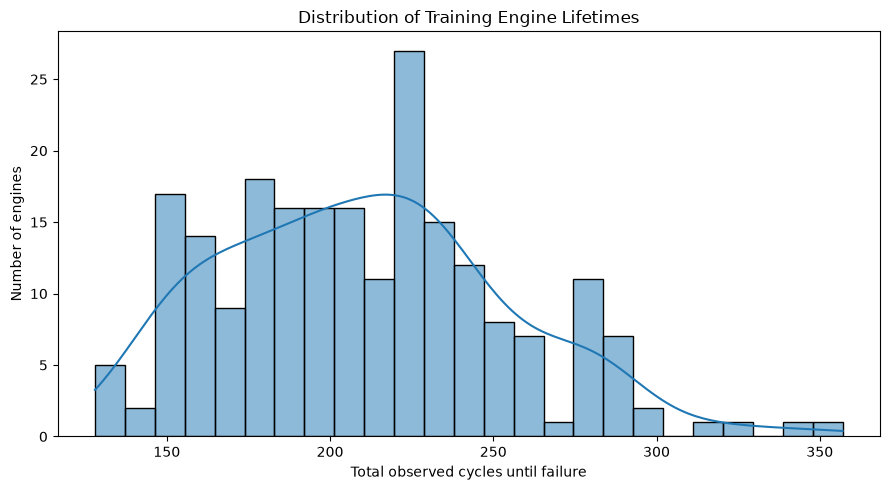

In [2]:

engine_lifetimes = train.groupby("engine_id")["cycle"].max()

print("Training engine lifetime statistics:")
print(engine_lifetimes.describe().round(2))

plt.figure(figsize=(9, 5))
sns.histplot(engine_lifetimes, bins=25, kde=True)
plt.xlabel("Total observed cycles until failure")
plt.ylabel("Number of engines")
plt.title("Distribution of Training Engine Lifetimes")
plt.tight_layout()
plt.show()


In [3]:

sensor_columns = [f"sensor_{i}" for i in range(1, 22)]

sensor_summary = train[sensor_columns].agg(["mean", "std", "min", "max"]).T
sensor_summary["unique_values"] = train[sensor_columns].nunique()

print(sensor_summary.round(4).to_string())


                mean       std        min        max  unique_values
sensor_1    472.8617   26.4602   445.0000   518.6700              6
sensor_2    579.5968   37.3911   535.6500   644.4300           1571
sensor_3   1419.9478  106.2870  1245.4300  1614.6600          11839
sensor_4   1205.6692  119.5509  1029.4900  1442.3600          14713
sensor_5      8.0299    3.6271     3.9100    14.6200              6
sensor_6     11.5968    5.4519     5.7100    21.6100             14
sensor_7    282.4698  146.5393   136.7500   555.7200           2004
sensor_8   2228.4064  145.5820  1914.8500  2388.3600            880
sensor_9   8523.5455  336.7807  7988.7400  9216.8300          20945
sensor_10     1.0950    0.1278     0.9300     1.3000              8
sensor_11    42.9919    3.2435    36.2100    48.3900            671
sensor_12   265.9433  138.1637   129.2400   523.4600           1633
sensor_13  2334.1854  128.4265  2027.7200  2390.7400            507
sensor_14  8065.5488   84.9641  7851.5900  8274.

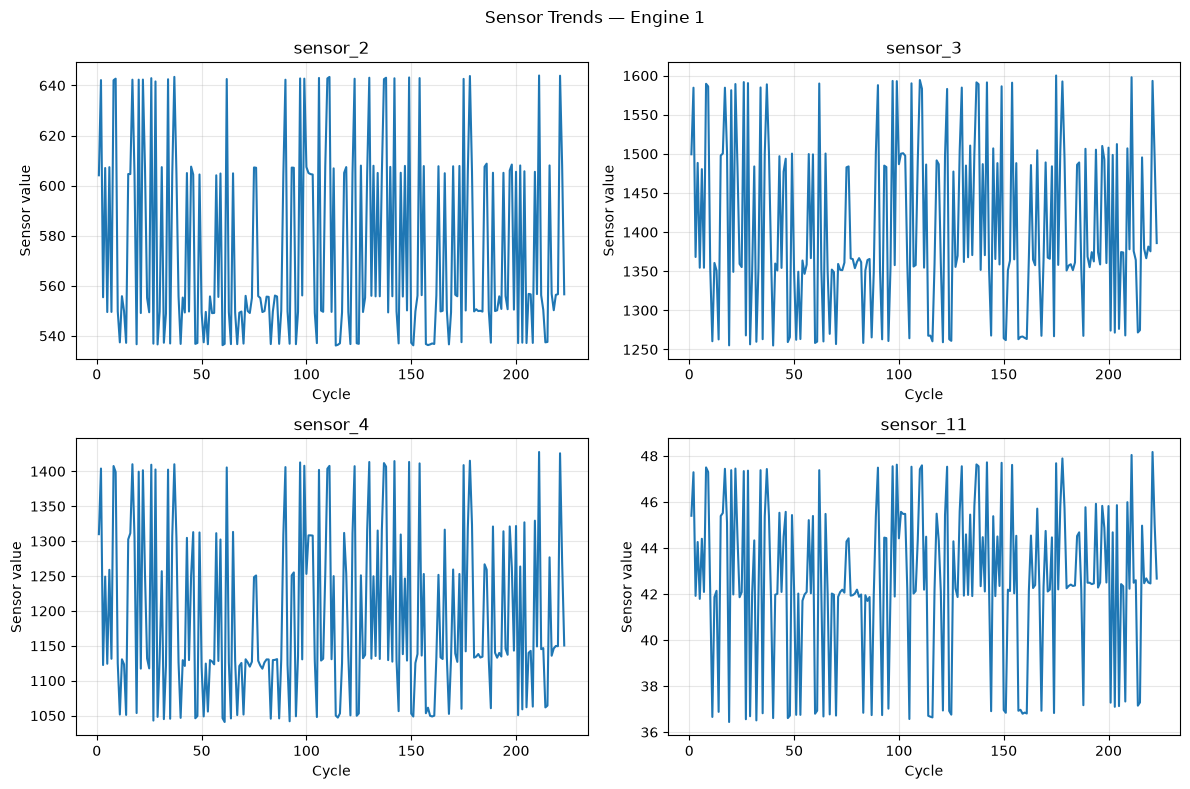

In [4]:

engine_id = 1
engine_data = train[train["engine_id"] == engine_id]

selected_sensors = ["sensor_2", "sensor_3", "sensor_4", "sensor_11"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, sensor in zip(axes.flat, selected_sensors):
    ax.plot(engine_data["cycle"], engine_data[sensor])
    ax.set_title(sensor)
    ax.set_xlabel("Cycle")
    ax.set_ylabel("Sensor value")
    ax.grid(True, alpha=0.3)

fig.suptitle(f"Sensor Trends — Engine {engine_id}")
plt.tight_layout()
plt.show()


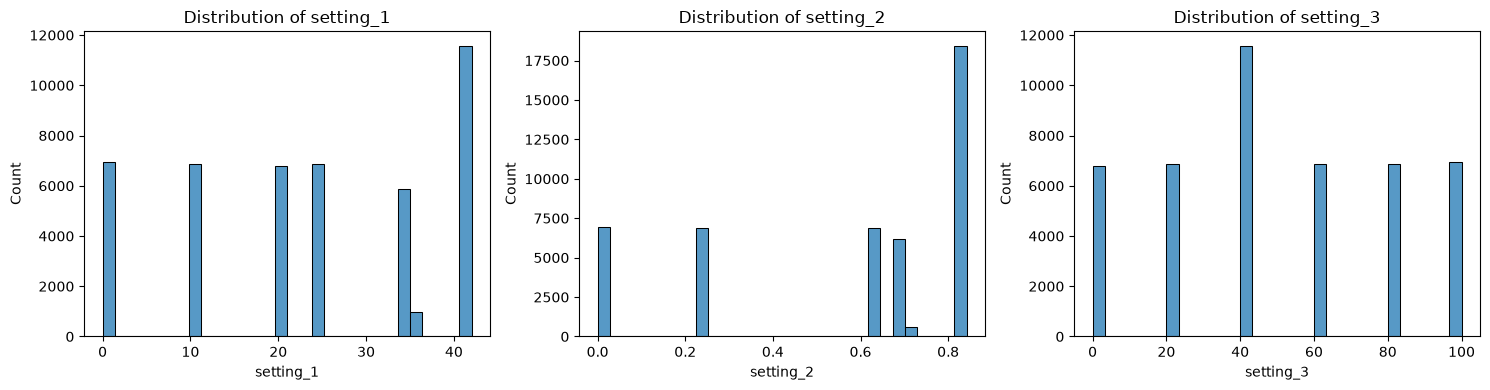

In [5]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, setting in zip(axes, ["setting_1", "setting_2", "setting_3"]):
    sns.histplot(data=train, x=setting, bins=30, ax=ax)
    ax.set_title(f"Distribution of {setting}")

plt.tight_layout()
plt.show()


In [6]:

# Generate RUL labels for training data only
train_labeled = train.copy()

final_cycles = (
    train_labeled.groupby("engine_id")["cycle"]
    .max()
    .rename("final_cycle")
)

train_labeled = train_labeled.join(
    final_cycles,
    on="engine_id",
)

train_labeled["RUL"] = (
    train_labeled["final_cycle"] - train_labeled["cycle"]
)

print(train_labeled[
    ["engine_id", "cycle", "final_cycle", "RUL"]
].head(10))

print("\nRUL summary:")
print(train_labeled["RUL"].describe())

# Verify labels reach zero at each training engine's final cycle
last_rows = train_labeled.loc[
    train_labeled.groupby("engine_id")["cycle"].idxmax()
]

assert (last_rows["RUL"] == 0).all()
print("\nValidation passed: every training engine ends at RUL = 0.")


   engine_id  cycle  final_cycle  RUL
0          1      1          223  222
1          1      2          223  221
2          1      3          223  220
3          1      4          223  219
4          1      5          223  218
5          1      6          223  217
6          1      7          223  216
7          1      8          223  215
8          1      9          223  214
9          1     10          223  213

RUL summary:
count    45918.000000
mean       109.307396
std         68.420545
min          0.000000
25%         52.000000
50%        105.000000
75%        159.000000
max        356.000000
Name: RUL, dtype: float64

Validation passed: every training engine ends at RUL = 0.


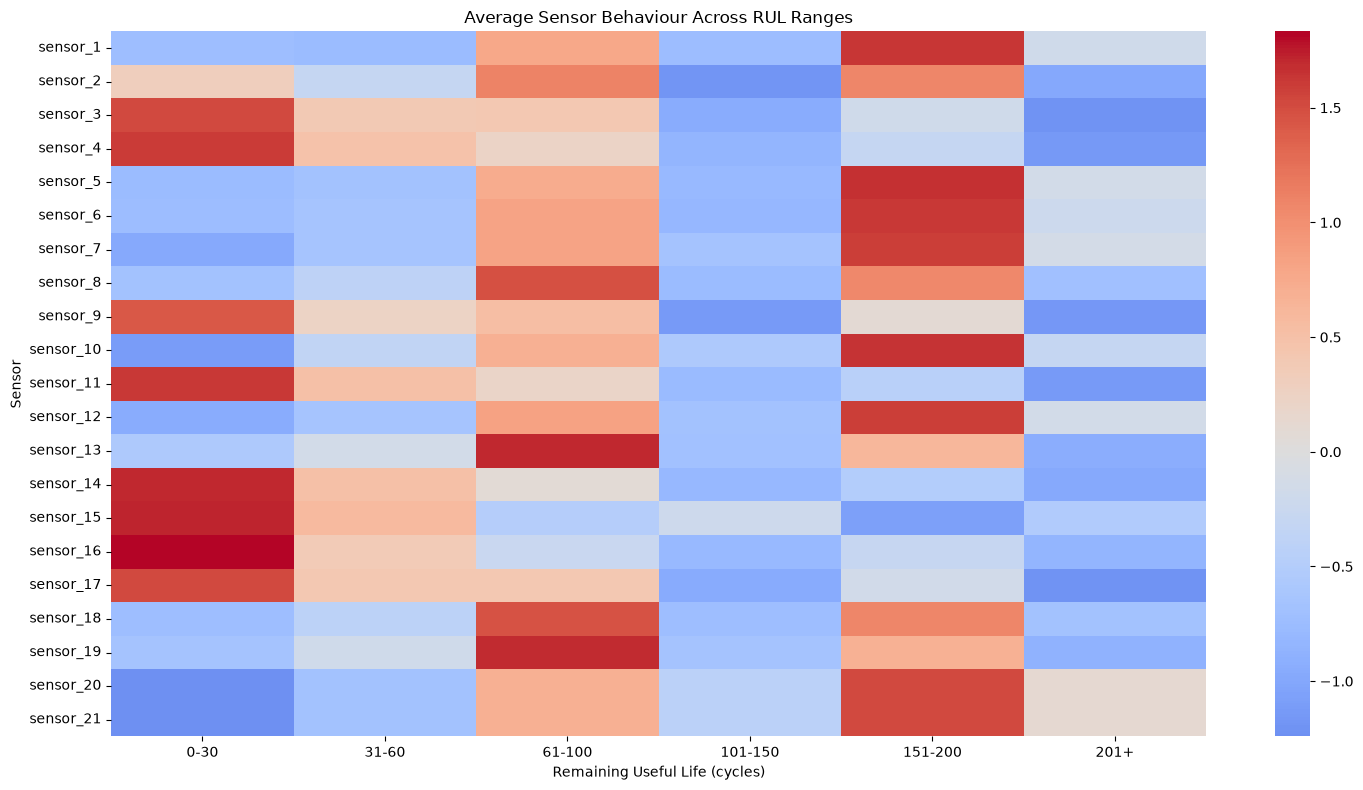

In [7]:

# Average sensor readings across RUL ranges
sensor_columns = [f"sensor_{i}" for i in range(1, 22)]

train_labeled["RUL_range"] = pd.cut(
    train_labeled["RUL"],
    bins=[-1, 30, 60, 100, 150, 200, float("inf")],
    labels=[
        "0-30", "31-60", "61-100",
        "101-150", "151-200", "201+"
    ],
)

sensor_by_rul = train_labeled.groupby(
    "RUL_range", observed=False
)[sensor_columns].mean()

# Standardize the averages for visualization only
sensor_trends = (
    sensor_by_rul - sensor_by_rul.mean()
) / sensor_by_rul.std()

plt.figure(figsize=(15, 8))
sns.heatmap(
    sensor_trends.T,
    cmap="coolwarm",
    center=0,
    xticklabels=True,
    yticklabels=True,
)
plt.title("Average Sensor Behaviour Across RUL Ranges")
plt.xlabel("Remaining Useful Life (cycles)")
plt.ylabel("Sensor")
plt.tight_layout()
plt.show()


In [8]:
print(sensor_by_rul.round(2).T.to_string())

RUL_range     0-30    31-60   61-100  101-150  151-200     201+
sensor_1    472.61   472.60   473.11   472.60   473.39   472.79
sensor_2    579.74   579.43   580.14   579.00   580.12   579.10
sensor_3   1425.59  1421.50  1421.55  1416.57  1419.39  1415.61
sensor_4   1215.37  1208.69  1207.11  1200.81  1204.08  1199.07
sensor_5      7.99     7.99     8.07     7.99     8.12     8.02
sensor_6     11.53    11.54    11.66    11.53    11.73    11.58
sensor_7    279.89   280.73   284.49   280.67   286.45   282.06
sensor_8   2226.90  2227.47  2231.35  2226.69  2230.49  2226.80
sensor_9   8535.32  8525.77  8528.21  8514.52  8524.54  8514.26
sensor_10     1.09     1.09     1.10     1.09     1.10     1.09
sensor_11    43.32    43.10    43.04    42.85    42.91    42.78
sensor_12   263.57   264.32   267.85   264.23   269.67   265.53
sensor_13  2333.23  2333.86  2336.68  2333.01  2335.04  2332.66
sensor_14  8075.76  8068.80  8066.23  8061.11  8062.87  8060.18
sensor_15     9.40     9.36     9.32    

In [9]:

from sklearn.model_selection import GroupShuffleSplit

# Split by engine, never by individual rows
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42,
)

train_idx, val_idx = next(
    splitter.split(
        train_labeled,
        groups=train_labeled["engine_id"],
    )
)

train_split = train_labeled.iloc[train_idx].copy()
val_split = train_labeled.iloc[val_idx].copy()

train_engines = set(train_split["engine_id"].unique())
val_engines = set(val_split["engine_id"].unique())

print("Training rows:", len(train_split))
print("Validation rows:", len(val_split))
print("Training engines:", len(train_engines))
print("Validation engines:", len(val_engines))
print("Overlapping engines:", len(train_engines & val_engines))

assert len(train_engines & val_engines) == 0
assert set(train_split["engine_id"]) | set(val_split["engine_id"]) == set(
    train_labeled["engine_id"].unique()
)

print("\nLeakage-safe engine split verified.")


Training rows: 36420
Validation rows: 9498
Training engines: 174
Validation engines: 44
Overlapping engines: 0

Leakage-safe engine split verified.


In [11]:
[(name, obj.shape) for name, obj in globals().items()
 if isinstance(obj, __import__("pandas").DataFrame)]

[('train', (45918, 26)),
 ('test', (29820, 26)),
 ('sensor_summary', (21, 5)),
 ('engine_data', (223, 26)),
 ('train_labeled', (45918, 29)),
 ('last_rows', (218, 28)),
 ('sensor_by_rul', (6, 21)),
 ('sensor_trends', (6, 21)),
 ('train_split', (36420, 29)),
 ('val_split', (9498, 29))]

In [12]:
print(train_split.columns.tolist())
print(train_split["RUL"].describe())

['engine_id', 'cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21', 'final_cycle', 'RUL', 'RUL_range']
count    36420.000000
mean       108.597172
std         68.078401
min          0.000000
25%         52.000000
50%        104.000000
75%        158.000000
max        356.000000
Name: RUL, dtype: float64


In [4]:
from pathlib import Path
import json
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# Paths
PROJECT_ROOT = Path(r"C:\Users\Moni\uncertainty-aware-rul-prediction")
DATA_DIR = PROJECT_ROOT / "data" / "raw" / "Challenge_Data"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Load training data
columns = (
    ["engine_id", "cycle", "setting_1", "setting_2", "setting_3"]
    + [f"sensor_{i}" for i in range(1, 22)]
)

train = pd.read_csv(
    DATA_DIR / "train.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

# Create RUL labels
train_labeled = train.copy()
final_cycles = train_labeled.groupby("engine_id")["cycle"].max()
train_labeled["RUL"] = (
    train_labeled["engine_id"].map(final_cycles)
    - train_labeled["cycle"]
)

# Split by engine, not by individual rows
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(train_labeled, groups=train_labeled["engine_id"])
)

train_split = train_labeled.iloc[train_idx].copy()
val_split = train_labeled.iloc[val_idx].copy()

train_engines = sorted(train_split["engine_id"].unique().tolist())
val_engines = sorted(val_split["engine_id"].unique().tolist())

assert set(train_engines).isdisjoint(set(val_engines))

# Save processed splits
train_split.to_csv(PROCESSED_DIR / "train_split.csv", index=False)
val_split.to_csv(PROCESSED_DIR / "validation_split.csv", index=False)

with open(PROCESSED_DIR / "split_metadata.json", "w") as f:
    json.dump({
        "random_state": 42,
        "validation_fraction": 0.2,
        "training_engines": train_engines,
        "validation_engines": val_engines
    }, f, indent=2)

print("Training rows:", len(train_split))
print("Validation rows:", len(val_split))
print("Training engines:", len(train_engines))
print("Validation engines:", len(val_engines))
print("Overlapping engines:", len(set(train_engines) & set(val_engines)))
print("Saved to:", PROCESSED_DIR)

Training rows: 36420
Validation rows: 9498
Training engines: 174
Validation engines: 44
Overlapping engines: 0
Saved to: C:\Users\Moni\uncertainty-aware-rul-prediction\data\processed
